## 다양한 이미지 증강 기법

각 셀을 위에서부터 하나씩 실행해 원본 MNIST 숫자와 증강 결과를 비교합니다.

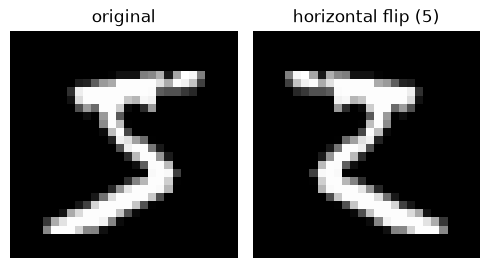

In [1]:
# Transpose: 좌우 반전
from pathlib import Path

import matplotlib.pyplot as plt
from torchvision import transforms
from torchvision.datasets import MNIST

project_root = Path.cwd().resolve()
if not (project_root / 'data').exists() and (project_root.parent / 'data').exists():
    project_root = project_root.parent

mnist = MNIST(root=project_root / 'data', train=True, download=True)
sample_image, sample_label = mnist[0]

def show_pair(original, augmented, title):
    fig, axes = plt.subplots(1, 2, figsize=(5, 3))
    for axis, image, name in zip(axes, [original, augmented], ['original', title]):
        axis.imshow(image, cmap='gray')
        axis.set_title(name)
        axis.axis('off')
    plt.tight_layout()
    plt.show()

horizontal_flip = transforms.RandomHorizontalFlip(p=1.0)
show_pair(sample_image, horizontal_flip(sample_image), f'horizontal flip ({sample_label})')

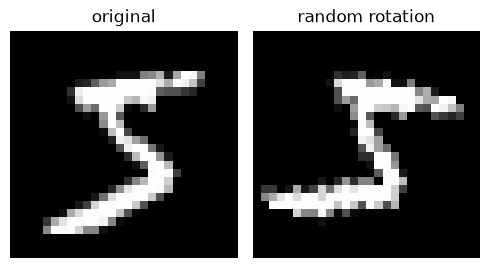

In [2]:
# Rotate: -20° ~ +20° 범위에서 무작위 회전
rotation = transforms.RandomRotation(degrees=45, fill=0)
show_pair(sample_image, rotation(sample_image), 'random rotation')

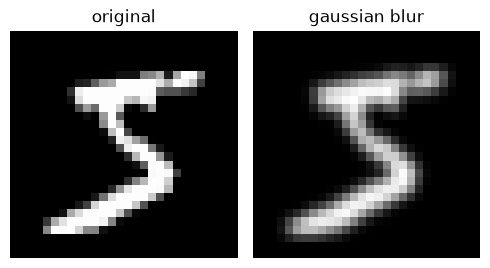

In [3]:
# Blur: 가우시안 블러로 초점이 약간 흐린 이미지 상황을 흉내 냅니다.
blur = transforms.GaussianBlur(kernel_size=3, sigma=(0.8, 0.8))
show_pair(sample_image, blur(sample_image), 'gaussian blur')

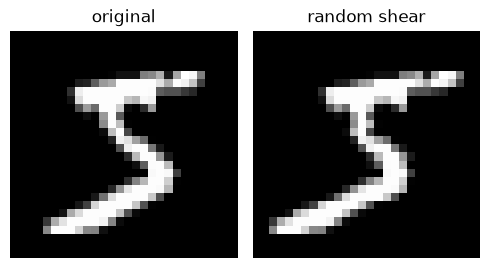

In [4]:
# Shear: 이미지를 한쪽 방향으로 기울입니다.
shear = transforms.RandomAffine(degrees=0, shear=30, fill=0)
show_pair(sample_image, shear(sample_image), 'random shear')

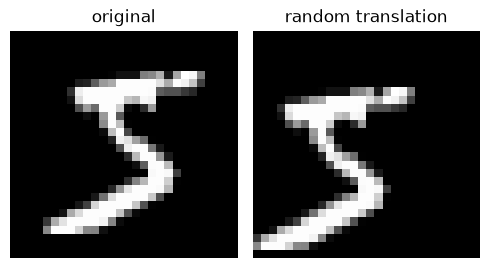

In [5]:
# Move: 가로·세로 방향으로 최대 15%만큼 평행 이동합니다.
translation = transforms.RandomAffine(degrees=0, translate=(0.15, 0.15), fill=0)
show_pair(sample_image, translation(sample_image), 'random translation')

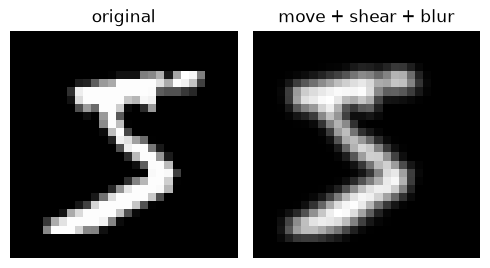

In [6]:
# 회전과 좌우 반전 없이 여러 증강 기법을 순서대로 조합합니다.
# 이동+기울임 → 블러
combined_augmentation = transforms.Compose([
    transforms.RandomAffine(
        degrees=0, translate=(0.15, 0.15), shear=20, fill=0
    ),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.8, 0.8)),
])

combined_image = combined_augmentation(sample_image)
show_pair(sample_image, combined_image, 'move + shear + blur')

## MNIST 데이터 증강 데이터셋 만들기

In [19]:
from pathlib import Path
import random
import shutil

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms
from torchvision.datasets import MNIST

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# 노트북을 프로젝트 루트 또는 2.argumentation 폴더에서 실행해도 동작합니다.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists() and (PROJECT_ROOT.parent / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / 'data'
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'val'

# 최종 개수: train 100 x 10 x (원본 1 + 증강 4) = 5,000장
#           val    20 x 10 x (원본 1 + 증강 4) = 1,000장
TRAIN_PER_CLASS = 100
VAL_PER_CLASS = 20

train_mnist = MNIST(root=DATA_DIR, train=True, download=True)
test_mnist = MNIST(root=DATA_DIR, train=False, download=True)
print(f'프로젝트 경로: {PROJECT_ROOT}')
print(f'원본 train: {len(train_mnist):,}장, test: {len(test_mnist):,}장')

프로젝트 경로: D:\workspace\ComputerVision_Recipe
원본 train: 60,000장, test: 10,000장


In [8]:
# 모두 PIL 이미지를 입력·출력으로 사용하므로 바로 PNG로 저장할 수 있습니다.
augmentations = {
    'rotation': transforms.RandomRotation(degrees=20, fill=0),
    'affine': transforms.RandomAffine(
        degrees=0, translate=(0.12, 0.12), scale=(0.85, 1.15), shear=10, fill=0
    ),
    'perspective': transforms.RandomPerspective(distortion_scale=0.3, p=1.0, fill=0),
    'blur': transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2)),
}
augmentations

{'rotation': RandomRotation(degrees=[-20.0, 20.0], interpolation=nearest, expand=False, fill=0),
 'affine': RandomAffine(degrees=[0.0, 0.0], translate=(0.12, 0.12), scale=(0.85, 1.15), shear=[-10.0, 10.0]),
 'perspective': RandomPerspective(p=1.0),
 'blur': GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 1.2))}

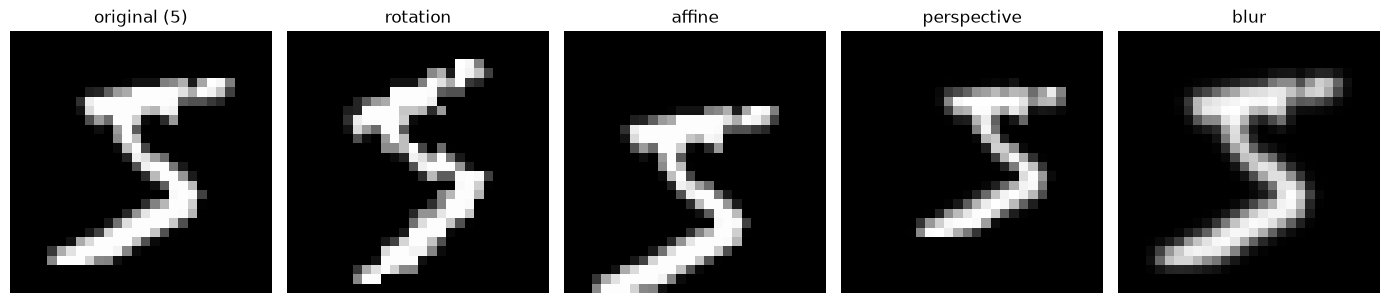

In [9]:
# 동일한 원본 숫자에 각 기법을 하나씩 적용해 비교합니다.
sample_image, sample_label = train_mnist[0]
fig, axes = plt.subplots(1, len(augmentations) + 1, figsize=(14, 3))
axes[0].imshow(sample_image, cmap='gray')
axes[0].set_title(f'original ({sample_label})')
axes[0].axis('off')

for axis, (name, augmentation) in zip(axes[1:], augmentations.items()):
    axis.imshow(augmentation(sample_image), cmap='gray')
    axis.set_title(name)
    axis.axis('off')

plt.tight_layout()
plt.show()

## 원본 + 합성 이미지 저장

아래 셀은 이 실습에서 만든 기존 `data/train`, `data/val`을 지우고 다시 만듭니다. 각 클래스 폴더에 원본(`original_...png`)과 증강 이미지(`rotation_...png` 등)를 저장합니다.

In [10]:
def reset_directory(directory: Path) -> None:
    """이 실습에서 만든 split 폴더만 비우고 다시 만듭니다."""
    if directory.exists():
        shutil.rmtree(directory)
    for label in range(10):
        (directory / str(label)).mkdir(parents=True, exist_ok=True)


def choose_balanced_indices(dataset: MNIST, per_class: int, seed: int) -> list[int]:
    generator = random.Random(seed)
    targets = dataset.targets.tolist()
    selected = []
    for label in range(10):
        candidates = [index for index, target in enumerate(targets) if target == label]
        selected.extend(generator.sample(candidates, per_class))
    return selected


def export_original_and_augmented(dataset: MNIST, output_dir: Path, per_class: int, seed: int) -> int:
    reset_directory(output_dir)
    saved_count = 0
    for index in choose_balanced_indices(dataset, per_class, seed):
        image = Image.fromarray(dataset.data[index].numpy(), mode='L')
        label = int(dataset.targets[index])
        class_dir = output_dir / str(label)
        image.save(class_dir / f'original_{index:05d}.png')
        saved_count += 1
        for name, augmentation in augmentations.items():
            augmentation(image).save(class_dir / f'{name}_{index:05d}.png')
            saved_count += 1
    return saved_count


train_count = export_original_and_augmented(train_mnist, TRAIN_DIR, TRAIN_PER_CLASS, SEED)
val_count = export_original_and_augmented(test_mnist, VAL_DIR, VAL_PER_CLASS, SEED + 1)
print(f'train 저장 완료: {train_count:,}장 -> {TRAIN_DIR}')
print(f'val 저장 완료:   {val_count:,}장 -> {VAL_DIR}')

train 저장 완료: 5,000장 -> D:\workspace\ComputerVision_Recipe\data\train
val 저장 완료:   1,000장 -> D:\workspace\ComputerVision_Recipe\data\val


In [11]:
from torchvision.datasets import ImageFolder

# ImageFolder는 파일을 RGB로 읽으므로, MNIST 모델 입력에 맞게 다시 1채널로 변환합니다.
folder_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])
train_folder_dataset = ImageFolder(TRAIN_DIR, transform=folder_transform)
val_folder_dataset = ImageFolder(VAL_DIR, transform=folder_transform)

print('클래스:', train_folder_dataset.classes)
print(f'ImageFolder train: {len(train_folder_dataset):,}장')
print(f'ImageFolder val:   {len(val_folder_dataset):,}장')
image_tensor, label = train_folder_dataset[0]
print(f'샘플 텐서 shape: {tuple(image_tensor.shape)}, label: {label}')

클래스: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
ImageFolder train: 5,000장
ImageFolder val:   1,000장
샘플 텐서 shape: (1, 28, 28), label: 0
